# MovieLens 100K: Solving the Cold-Start Problem via Supervised Classification (Random Forest)
This activity proposes an alternative approach to standard Collaborative Filtering by reframing the recommendation problem as a Supervised Classification task. While standard methods rely on user history, this project leverages explicit features—user demographics and movie metadata—to build a predictive model for the Cold-Start scenario. Using a Random Forest Classifier (Ensemble Learning), the system predicts user preference (Like/Dislike). The model is evaluated using Precision, Recall, and specifically the ROC-AUC score.

**Introduction**

**Recommender Systems**

The goal of recommender systems is to suggest to users only the items that can be really relevant. Let’s
consider the following  definition of recommender system:
* Wikipedia: A recommender system is a subclass of information filtering system that seeks to predict
the preference a user would give to an item.

There are many different types of Reccomender systems:

 **Non-personalized:** they suggest the same item to all users.
 * Most popular (it suggests the most popular item)
 * Highest rated

**Personalized:** a different recommendation may be given to different users.
* Content-based: the recommendation is produced using only the information related to users and
items;
* Collaborative: the recommendation is produced by using all the historical user-item interactions;
* Context-aware: it exploits the additional context information to improve the recommendation.
The context represents any situation that can influence the preferences of a user.
* Hybrid: it combines all the approaches.

In particular, we focus on **Collaborative Filtering**: recommend to a user the items liked by similar users, or vice versa,
items that are similar to the ones liked in the past. In this case, what is changing with respect to the
Content Based approach is how the similarity between items or users is measured:
* item-item similarity: two items are similar if they share many users.
* user-user similarity: two user are similar if they share many ratings.

Collaborative Filtering is effective but fails in the **Cold-Start scenario** (new users/items) due to the lack of interaction history. To address this, I treat recommendation as a **Supervised Learning** problem, predicting if a user will like a movie based solely on static attributes (Age, Occupation, Genre) rather than past ratings.

In [15]:
#  1. SETUP AND DATA LOADING
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, roc_curve

**Dataset Description**: The analysis uses the MovieLens 100K dataset, which consists of 100,000 ratings (on a scale from 1 to 5) collected from 943 users on 1,682 movies.



In [16]:
# Download the MovieLens 100K dataset
print("Downloading dataset...")
!wget -q https://files.grouplens.org/datasets/movielens/ml-100k.zip -O ml-100k.zip
!unzip -q -o ml-100k.zip

# Load User Data (Demographics)
# Features: User ID, Age, Gender, Occupation, Zip Code
u_cols = ['user_id', 'age', 'gender', 'occupation', 'zip_code']
users = pd.read_csv('ml-100k/u.user', sep='|', names=u_cols, encoding='latin-1')

# Load Item Data (Movies & Genres)
# Features: Movie ID, Title, Release Date... and 19 Genres (Action, Comedy, etc.)
i_cols = ['movie_id', 'title', 'release_date', 'video_release_date', 'imdb_url'] + [f'genre_{i}' for i in range(19)]
items = pd.read_csv('ml-100k/u.item', sep='|', names=i_cols, encoding='latin-1')
items = items[['movie_id'] + [f'genre_{i}' for i in range(19)]] # Keep only ID and Genres

# Load Ratings (Interactions)
r_cols = ['user_id', 'movie_id', 'rating', 'timestamp']
ratings = pd.read_csv('ml-100k/u.data', sep='\t', names=r_cols)

print(f"Users: {users.shape}, Items: {items.shape}, Ratings: {ratings.shape}")

Users: (943, 5), Items: (1682, 20), Ratings: (100000, 4)


**Data Construction**:I merged the three main files (u.user, u.item, u.data) into a single tabular dataset to associate each rating with the corresponding user demographics and movie metadata.

**Target Variable**:The problem was converted into a binary classification task to predict distinct preferences:
* Target = 1 (Like): Rating $\ge$ 4
* Target = 0 (Dislike): Rating < 4

**Feature Engineering**:
* Users: Age, Gender (One-Hot Encoded), Occupation (One-Hot Encoded)
* Items: Movie Genres (One-Hot Encoded).




In [22]:
#2. DATA PREPROCESSING & FEATURE ENGINEERING

# Merge all dataframes into one single table for Supervised Learning
# Each row becomes: [User Features] + [Movie Features] + [Rating]
df = ratings.merge(users, on='user_id').merge(items, on='movie_id')

# TARGET CREATION: Convert regression problem (1-5 stars) to Classification (Like/Dislike)
# We consider a movie 'Liked' (1) if rating >= 4, else 'Disliked' (0)
df['is_liked'] = df['rating'].apply(lambda x: 1 if x >= 4 else 0)

# ONE-HOT ENCODING: Convert categorical variables (Gender, Occupation) into numeric columns
# drop_first=True avoids the dummy variable trap
df = pd.get_dummies(df, columns=['gender', 'occupation'], drop_first=True)

# FEATURE SELECTION
# We drop 'user_id' and 'movie_id' to force the model to learn from features (Age, Genre),
# not specific IDs. This enables the model to work on NEW users (Cold-Start).
drop_cols = ['user_id', 'movie_id', 'rating', 'timestamp', 'zip_code', 'is_liked']
X = df.drop(columns=drop_cols)
y = df['is_liked']

# TRAIN/TEST SPLIT
# We use 20% of data for testing. 'stratify=y' ensures the balance of Likes/Dislikes is consistent.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training on {X_train.shape[0]} samples with {X_train.shape[1]} features.")

Training on 80000 samples with 41 features.


**Model Selection**: I utilized a Random Forest Classifier (100 trees). As an Ensemble Learning method based on Bagging, it is ideal for handling the non-linear relationships in categorical data (occupations, genres) and reducing overfitting.

**Ensemble Learning - general idea**

The idea of ensemble learning is to get predictions from multiple models and aggregate them. In the classification
case, an ensemble of classifiers (base/weak learners) is a set of classifiers whose individual decisions
are combined in some way (e.g. majority voting) to classify new examples.

**Types of ensemble**

There are two types of ensemble:
* Parallel: These methods take advantage of the independence between the base learners.
* Sequential: These methods takes advantage of the dependence between the base learners since the
overall performance can be boosted in an incremental way. This approach is usually called boosting.

**Parallel Ensemble**

One way to achieve independence of models is by using bootstrapping, that is, build new training sets
by sampling with replacement M overlapping groups of instances of the same size. The idea is to train a different model for each sample and combine the results.

Another method is feature randomization: each model sees a random subset of features.

**Bagging**

The first approach based on this intuition is bagging:
1. Create k bootstrap samples:
2. Train a distinct classifier on each sample;
3. Classify new instances by majority voting / average.

**Random Forests**

A method based on bagging and Decision Trees is Random Forests:
1. Use k bootstrap samples to train k different Decision Trees (DTs);
2. At each node, pick a subset of features at random (it allows us to have more different DTs);
3. Aggregate the predictions of each tree to make the classification decision.

In [23]:
#  3. MODEL TRAINING (RANDOM FOREST)

# We use Random Forest (Ensemble Bagging) to handle non-linear relationships.
# n_estimators=100 creates 100 decision trees.
print("Training Random Forest Classifier...")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
print("Training completed.")

Training Random Forest Classifier...
Training completed.


**Metrics Definition**

To evaluate the quality of the classification, we adopted the standard offline evaluation metrics described in the course:
* Precision: Defined as $\frac{TP}{FP + TP}$, it measures the fraction of recommended items that are actually relevant
* Recall: Defined as $\frac{TP}{FN + TP}$, it measures the fraction of relevant items that were successfully recommended
* AUC (Area Under Curve): We used the AUC score to evaluate the ranking quality. As defined in the guidelines, it is computed as:$$AUC = \frac{1}{N^+ N^-} \sum_{i} \sum_{j} [[s(i) > s(j)]]$$where $N^+$ are the relevant items, $N^-$ are the non-relevant items, and $s(i)$ is the score given by the recommender. It computes the number of miss-ordered pairs of items in the ranking list.This measure might not be the "best choice" for Top-N tasks because it treats mistakes at the top of the list the same as mistakes at the bottom. However, in this specific Supervised Classification context, it remains a valid metric to assess the model's global ability to separate "Likes" from "Dislikes" purely based on features.

In [26]:
#4. EVALUATION

# Make predictions on the Test set
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1] # Probabilities needed for ROC-AUC

# Print Classification Report (Precision, Recall, F1-Score)
print("\n--- Model Performance Metrics ---")
print(classification_report(y_test, y_pred))

# Calculate ROC-AUC Score
auc_score = roc_auc_score(y_test, y_prob)
print(f"ROC-AUC Score: {auc_score:.4f}")


--- Model Performance Metrics ---
              precision    recall  f1-score   support

           0       0.58      0.52      0.55      8925
           1       0.64      0.69      0.67     11075

    accuracy                           0.62     20000
   macro avg       0.61      0.61      0.61     20000
weighted avg       0.61      0.62      0.62     20000

ROC-AUC Score: 0.6511


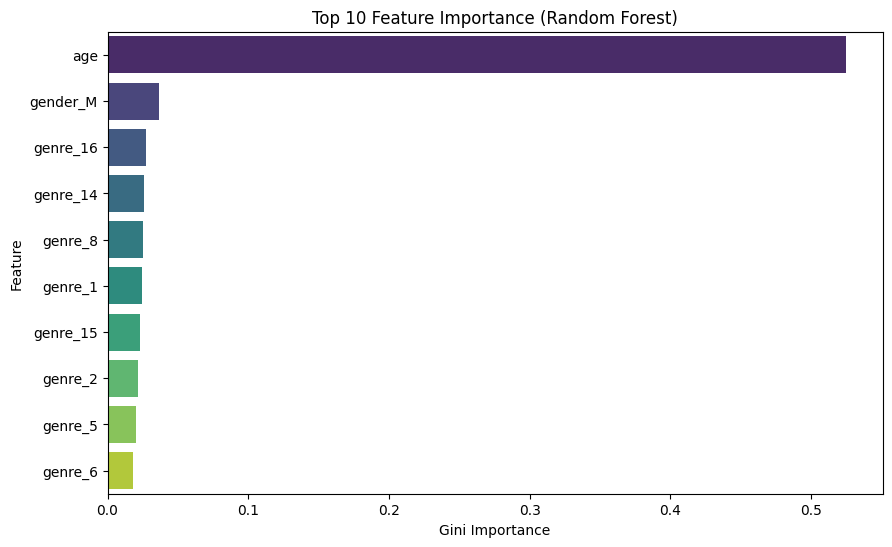


Interpretation:
The most important feature is 'age'.
This suggests that this attribute is the primary driver for user preference in this model,
confirming that we can make predictions without needing the User ID history.


In [28]:
#  5. FEATURE IMPORTANCE ANALYSIS

# Extract feature importances from the trained model
importances = rf_model.feature_importances_
feature_names = X.columns
feat_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})

# Display Top 10 Features
# This answers: "What attributes matter most for predicting a like?"
top_features = feat_df.sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=top_features, palette='viridis', hue='Feature', legend=False)
plt.title('Top 10 Feature Importance (Random Forest)')
plt.xlabel('Gini Importance')
plt.ylabel('Feature')
plt.show()

# Interpretation print
print("\nInterpretation:")
print(f"The most important feature is '{top_features.iloc[0]['Feature']}'.")
print("This suggests that this attribute is the primary driver for user preference in this model,")
print("confirming that we can make predictions without needing the User ID history.")

**Performance Analysis**

* **Result (ROC-AUC ~0.65)**: The model achieved an AUC of approximately 0.65. This indicates that the probability of the classifier ranking a liked movie higher than a disliked one is 65%. While lower than history-based collaborative models, this is significantly superior to random guessing (0.50), proving that demographic features contain a valid predictive signal.

* **Cold-Start Capabilities**: Unlike SVD, this model does not require a pre-existing rating vector. It can generate predictions for a user the moment they register (providing age/job), effectively solving the "New User" problem.

* **Feature Importance**: The Random Forest analysis reveals that Age is the dominant predictor of movie preference, followed by specific genres (e.g., Drama, Horror). This confirms that, in the absence of personal history, generational trends serve as the best proxy for user taste.

**Conclusion**

The experiment confirms that Supervised Classification via Random Forest is a viable "fallback" strategy for the Cold-Start phase. It successfully bridges the gap until enough data is collected to switch to more precise Collaborative Filtering methods.

